# BCS 3101 Capstone: Diabetes Prediction

# **Importing Libraries**

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import joblib
from importlib.metadata import version
from IPython.display import display

In [2]:
# Pipeline, imputer, scaler and PCA
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
# The models we will use
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [4]:
# Splitting, cross validation and tuning
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.inspection import permutation_importance

In [5]:
# Metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report, make_scorer)

In [7]:
# Settings
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import matplotlib.pyplot as plt

SEED = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

In [8]:
colors = {0: "#2E86AB", 1: "#E4572E"}
class_names = {0: "No diabetes", 1: "Diabetes"}

# **Loading the Data**

In [9]:
filepath = "/content/diabetes.csv"
cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

df = pd.read_csv(filepath, header=None, names=cols)

# **Descriptive Statistics**

In [10]:

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
1,6,148,72,35,0,33.6,0.627,50,1
2,1,85,66,29,0,26.6,0.351,31,0
3,8,183,64,0,0,23.3,0.672,32,1
4,1,89,66,23,94,28.1,0.167,21,0


In [11]:
df.shape

(769, 9)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 769 entries, 0 to 768
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Pregnancies               769 non-null    object
 1   Glucose                   769 non-null    object
 2   BloodPressure             769 non-null    object
 3   SkinThickness             769 non-null    object
 4   Insulin                   769 non-null    object
 5   BMI                       769 non-null    object
 6   DiabetesPedigreeFunction  769 non-null    object
 7   Age                       769 non-null    object
 8   Outcome                   769 non-null    object
dtypes: object(9)
memory usage: 54.2+ KB


In [13]:
df.describe().T

,count,unique,top,freq
Pregnancies,769,18,1,135
Glucose,769,137,100,17
BloodPressure,769,48,70,57
SkinThickness,769,52,0,227
Insulin,769,187,0,374
BMI,769,249,32,13
DiabetesPedigreeFunction,769,518,0.258,6
Age,769,53,22,72
Outcome,769,3,0,500


In [14]:
# Missing values in the raw file
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


# **Hidden Missing Values**

In [15]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

In [16]:
# How many zeros in each
(df[zero_cols] == 0).sum()

,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0


In [17]:
((df[zero_cols] == 0).mean() * 100).round(1)

,0
Glucose,0.0
BloodPressure,0.0
SkinThickness,0.0
Insulin,0.0
BMI,0.0


In [18]:
data = df.copy()
data[zero_cols] = data[zero_cols].replace(0, np.nan)

In [19]:
# Count of NaN now
data.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


# **Data Visualization**

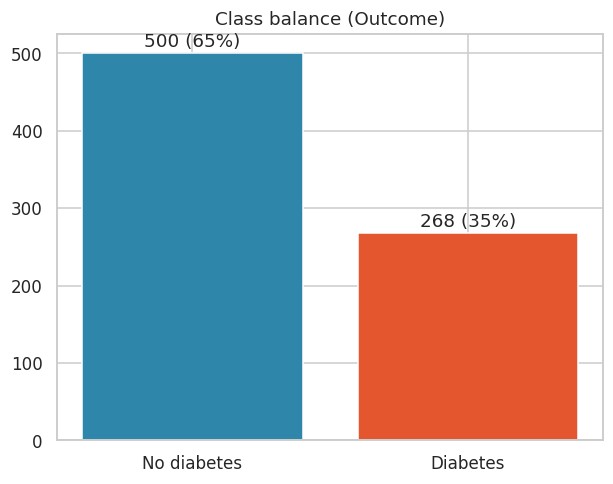

In [22]:
# Is the data balanced
valid_data = data[data["Outcome"].isin([0, 1, "0", "1"])].copy()
valid_data["Outcome"] = valid_data["Outcome"].astype(int)

counts = valid_data["Outcome"].value_counts().sort_index()
plt.bar(["No diabetes", "Diabetes"], counts.values, color=[colors[0], colors[1]])
for i, v in enumerate(counts.values):
    plt.text(i, v + 8, f"{v} ({v / len(valid_data):.0%})", ha="center")
plt.title("Class balance (Outcome)")
plt.show()

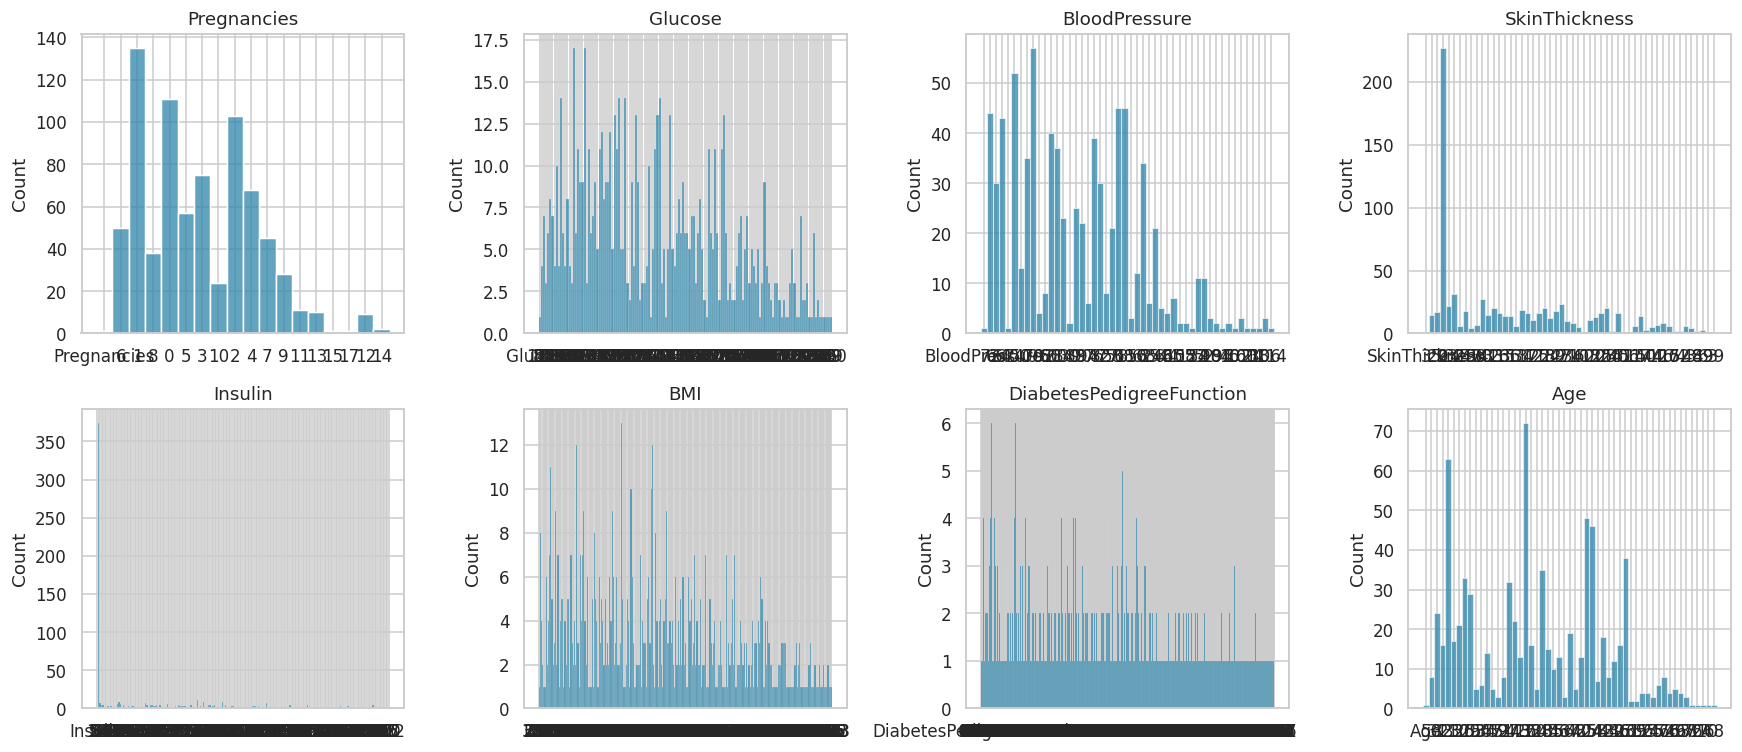

In [23]:
# Histogram of each feature
features = [c for c in data.columns if c != "Outcome"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data[col].dropna(), bins=20, ax=ax, color=colors[0])
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1120/661828063.py:4: UserWarning: 
The palette list has fewer values (2) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(data=data, x="Outcome", y=col, hue="Outcome", legend=False,
/tmp/ipykernel_1120/661828063.py:4: UserWarning: 
The palette list has fewer values (2) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(data=data, x="Outcome", y=col, hue="Outcome", legend=False,
/tmp/ipykernel_1120/661828063.py:4: UserWarning: 
The palette list has fewer values (2) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(data=data, x="Outcome", y=col, hue="Outcome", legend=False,
/tmp/ipykernel_1120/661828063.py:4: UserWarning: 
The palette list has fewer values (2) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(data=data, x="Outcome", y=col, hue="Outcome", legend=False,
/tmp/ipykernel_1120/661828063.py:4: UserWarning: 
Th

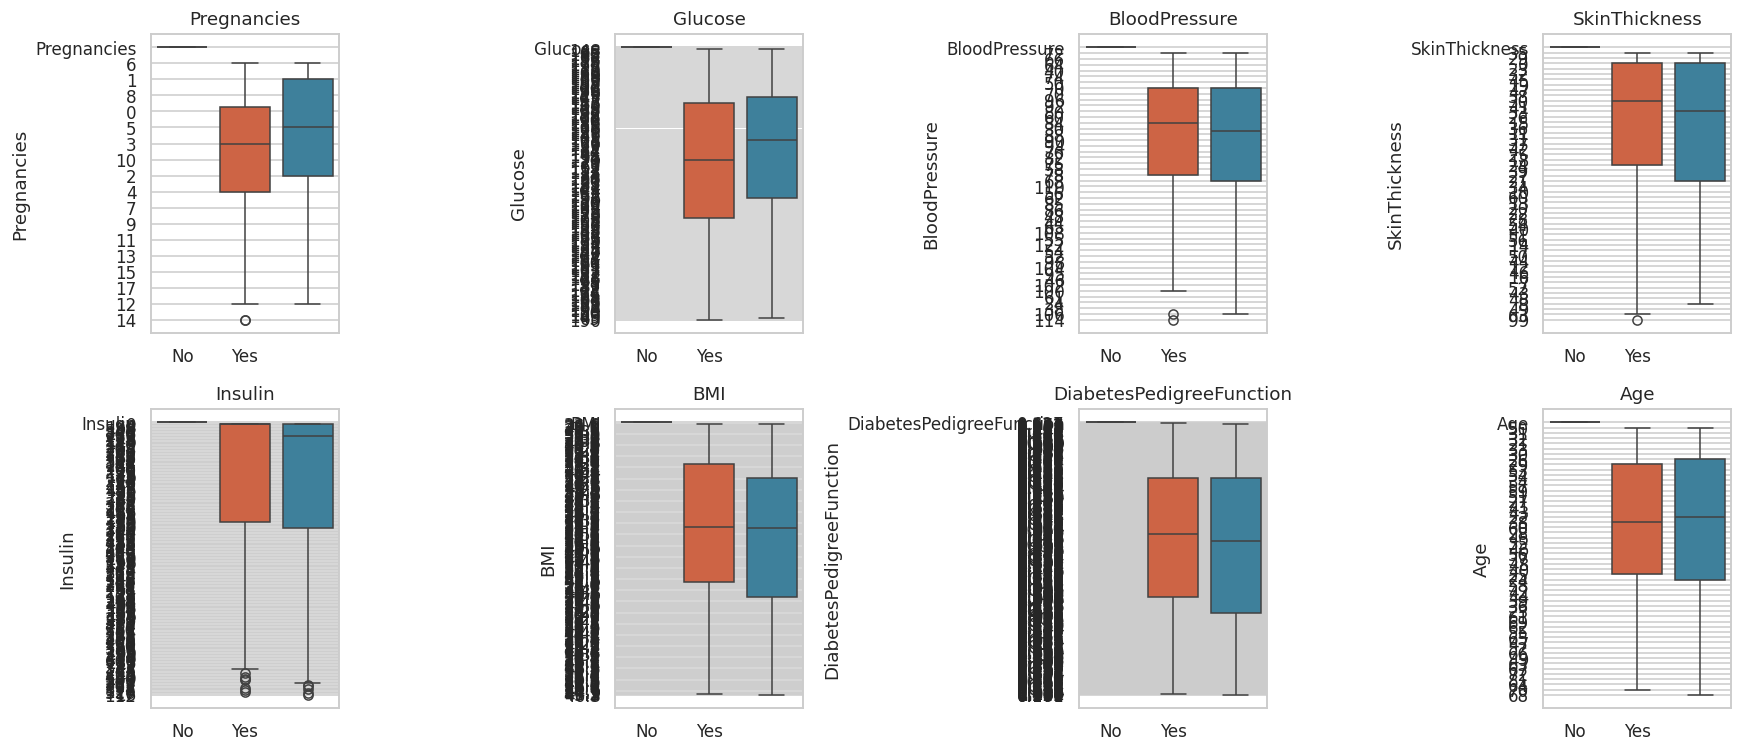

In [24]:
# Boxplot of each feature
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=data, x="Outcome", y=col, hue="Outcome", legend=False,
                palette=[colors[0], colors[1]], ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No", "Yes"])
    ax.set_xlabel("")
    ax.set_title(col)
plt.tight_layout()
plt.show()

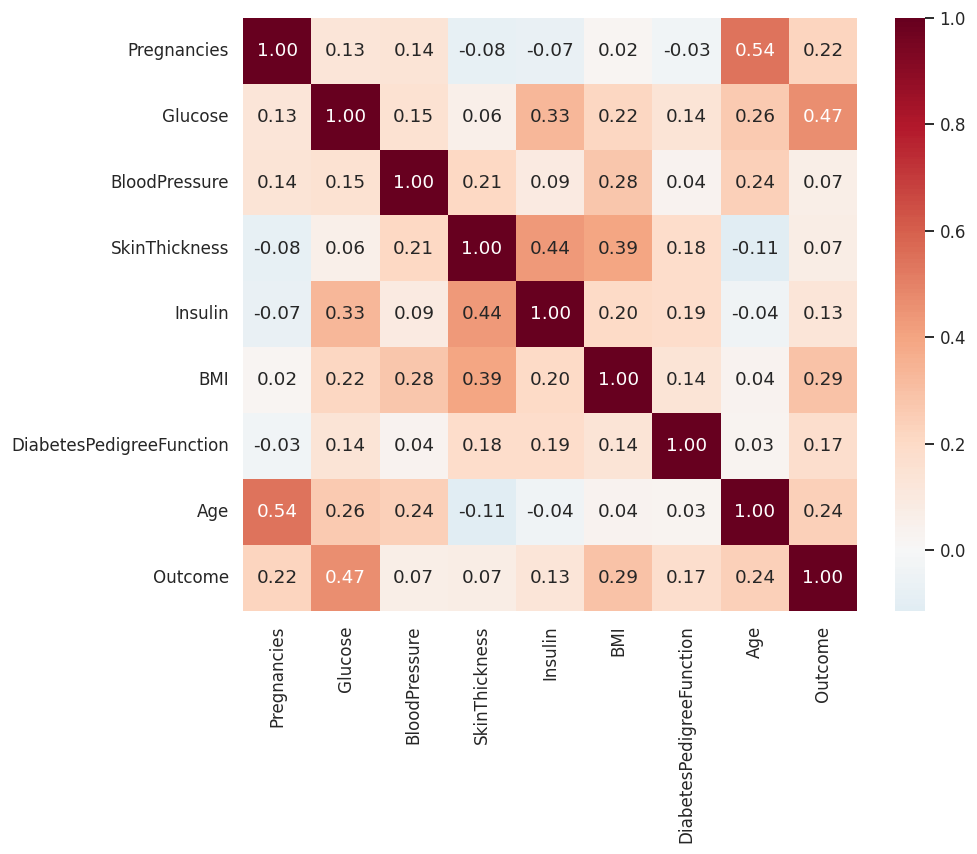

In [27]:
# Clean and cast to numeric before plotting correlation
clean_numeric_data = data[data["Outcome"].isin([0, 1, "0", "1"])].copy()
for col in clean_numeric_data.columns:
    clean_numeric_data[col] = pd.to_numeric(clean_numeric_data[col], errors="coerce")

# Correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(clean_numeric_data.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.show()

In [30]:
clean_numeric_data.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(3)

,Outcome
Glucose,0.467
BMI,0.293
Age,0.238
Pregnancies,0.222
DiabetesPedigreeFunction,0.174
Insulin,0.131
SkinThickness,0.075
BloodPressure,0.065


# **Train/Test Split**

In [31]:
# Splitting X and y
X = data.drop(columns="Outcome")
y = data["Outcome"]

In [34]:
# Extract features and targets from clean_numeric_data
X = clean_numeric_data.drop(columns="Outcome")
y = clean_numeric_data["Outcome"]

# Split train and test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

In [35]:
# Checking dimensions
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (614, 8)
X_test shape: (154, 8)


In [36]:
print("Train:", y_train.mean().round(3))
print("Test :", y_test.mean().round(3))

Train: 0.349
Test : 0.351


# **Pipeline (no data leakage)**

In [37]:
def make_pipe(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

In [38]:
make_pipe(LogisticRegression())

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('model', LogisticRegression())])

# **Our Data Modelling**

In [39]:
models = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "SVM (RBF)": SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=SEED),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, random_state=SEED),
}

# **Cross Validation**

In [40]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

In [41]:
cv_repeated = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

In [42]:
def cv_table(model_dict, X_, y_, cv):
    rows, raw = [], {}
    for name, m in model_dict.items():
        est = m if isinstance(m, Pipeline) else make_pipe(m)
        res = cross_validate(est, X_, y_, cv=cv, scoring=scoring, n_jobs=-1)
        raw[name] = res
        row = {"Model": name}
        for k in scoring:
            row[k + "_mean"] = res["test_" + k].mean()
            row[k + "_std"] = res["test_" + k].std()
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model"), raw

In [43]:
# Function: show scores as mean ± std
def pretty(tbl):
    out = pd.DataFrame(index=tbl.index)
    labels = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall",
              "f1": "F1", "roc_auc": "ROC-AUC"}
    for k, label in labels.items():
        out[label] = tbl[k + "_mean"].map("{:.3f}".format) + " ± " + tbl[k + "_std"].map("{:.3f}".format)
    return out

In [44]:
cv_tbl, cv_raw = cv_table(models, X_train, y_train, cv_repeated)
cv_tbl = cv_tbl.sort_values("roc_auc_mean", ascending=False)

In [45]:
# Results (mean ± std)
pretty(cv_tbl)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.782 ± 0.036,0.746 ± 0.077,0.578 ± 0.062,0.648 ± 0.056,0.831 ± 0.040
SVM (RBF),0.764 ± 0.029,0.713 ± 0.075,0.566 ± 0.067,0.625 ± 0.041,0.830 ± 0.033
Random Forest,0.756 ± 0.036,0.693 ± 0.077,0.560 ± 0.059,0.615 ± 0.047,0.823 ± 0.042
Gradient Boosting,0.759 ± 0.034,0.697 ± 0.068,0.561 ± 0.070,0.618 ± 0.053,0.823 ± 0.035
Naive Bayes,0.767 ± 0.032,0.695 ± 0.071,0.608 ± 0.064,0.645 ± 0.046,0.820 ± 0.042
KNN,0.749 ± 0.028,0.714 ± 0.077,0.480 ± 0.064,0.570 ± 0.050,0.811 ± 0.038
Decision Tree,0.734 ± 0.046,0.646 ± 0.098,0.573 ± 0.111,0.597 ± 0.079,0.775 ± 0.055
Baseline (majority class),0.651 ± 0.002,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000


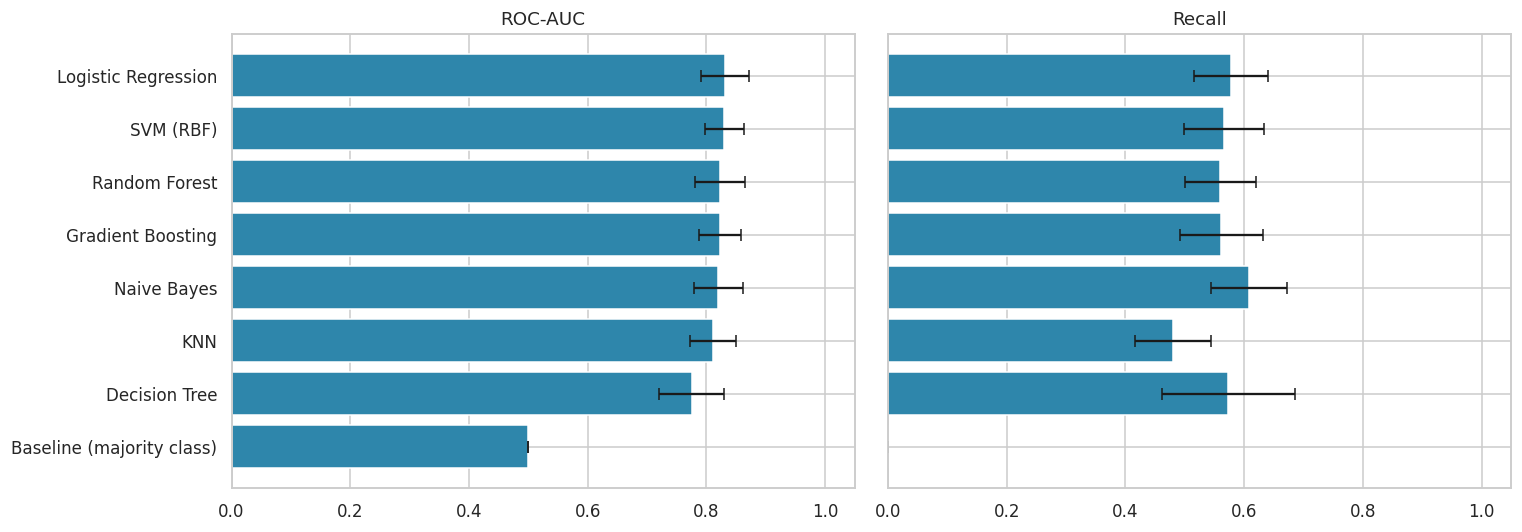

In [46]:
# Chart: ROC-AUC and recall with the spread
order = cv_tbl.index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, k, title in zip(axes, ["roc_auc", "recall"], ["ROC-AUC", "Recall"]):
    ax.barh(order, cv_tbl.loc[order, k + "_mean"], xerr=cv_tbl.loc[order, k + "_std"],
            color=colors[0], capsize=4)
    ax.set_title(title)
    ax.set_xlim(0, 1.05)
plt.tight_layout()
plt.show()

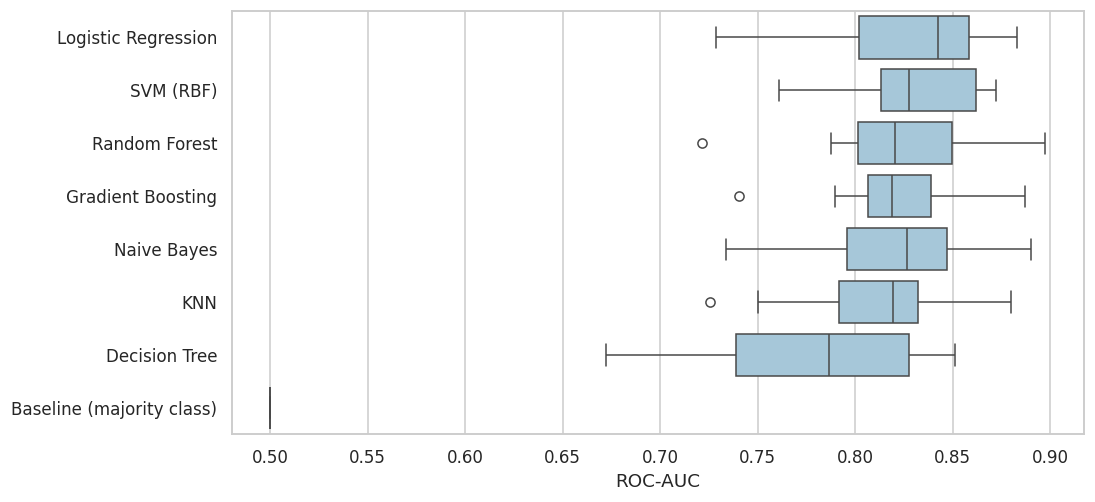

In [47]:
# Chart: how stable is each model? (ROC-AUC over the 15 folds)
spread = pd.DataFrame({n: r["test_roc_auc"] for n, r in cv_raw.items()})[cv_tbl.index]
plt.figure(figsize=(10, 5))
sns.boxplot(data=spread, orient="h", color="#9ecae1")
plt.xlabel("ROC-AUC")
plt.show()

# **Hyperparameter Tuning (GridSearchCV)**

In [48]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]},
    "KNN": {"model__n_neighbors": list(range(3, 32, 2)), "model__weights": ["uniform", "distance"]},
    "SVM (RBF)": {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01, 0.1]},
    "Naive Bayes": {"model__var_smoothing": list(np.logspace(-9, -5, 5))},
    "Decision Tree": {"model__max_depth": [2, 3, 4, 5, 6, 8], "model__min_samples_leaf": [1, 5, 10, 20]},
    "Random Forest": {"model__n_estimators": [200, 400], "model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 3, 5]},
    "Gradient Boosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.05, 0.1], "model__max_depth": [2, 3]},
}

In [49]:
# The two best models
top_two = cv_tbl.drop(index="Baseline (majority class)").index[:2].tolist()
top_two

['Logistic Regression', 'SVM (RBF)']

In [50]:
# Tuning both of them
cv_grid = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tuned = {}

for name in top_two:
    gs = GridSearchCV(make_pipe(models[name]), param_grids[name],
                      scoring="roc_auc", cv=cv_grid, n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name + " (tuned)"] = gs
    print(name)
    print("  best parameters:", {k.replace("model__", ""): v for k, v in gs.best_params_.items()})
    print("  best ROC-AUC   :", round(gs.best_score_, 3))

Logistic Regression
  best parameters: {'C': 0.1, 'class_weight': None}
  best ROC-AUC   : 0.835
SVM (RBF)
  best parameters: {'C': 1, 'gamma': 0.1}
  best ROC-AUC   : 0.84


In [51]:
# Checking the tuned models with the same cross validation as the others
tuned_estimators = {n: gs.best_estimator_ for n, gs in tuned.items()}
tuned_tbl, tuned_raw = cv_table(tuned_estimators, X_train, y_train, cv_repeated)

In [52]:
# All models together
full_tbl = pd.concat([cv_tbl, tuned_tbl]).sort_values("roc_auc_mean", ascending=False)
pretty(full_tbl)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
SVM (RBF) (tuned),0.767 ± 0.030,0.717 ± 0.073,0.569 ± 0.060,0.629 ± 0.041,0.834 ± 0.033
Logistic Regression (tuned),0.776 ± 0.031,0.746 ± 0.078,0.556 ± 0.059,0.633 ± 0.048,0.832 ± 0.040
Logistic Regression,0.782 ± 0.036,0.746 ± 0.077,0.578 ± 0.062,0.648 ± 0.056,0.831 ± 0.040
SVM (RBF),0.764 ± 0.029,0.713 ± 0.075,0.566 ± 0.067,0.625 ± 0.041,0.830 ± 0.033
Random Forest,0.756 ± 0.036,0.693 ± 0.077,0.560 ± 0.059,0.615 ± 0.047,0.823 ± 0.042
Gradient Boosting,0.759 ± 0.034,0.697 ± 0.068,0.561 ± 0.070,0.618 ± 0.053,0.823 ± 0.035
Naive Bayes,0.767 ± 0.032,0.695 ± 0.071,0.608 ± 0.064,0.645 ± 0.046,0.820 ± 0.042
KNN,0.749 ± 0.028,0.714 ± 0.077,0.480 ± 0.064,0.570 ± 0.050,0.811 ± 0.038
Decision Tree,0.734 ± 0.046,0.646 ± 0.098,0.573 ± 0.111,0.597 ± 0.079,0.775 ± 0.055


In [53]:
# Save the table
os.makedirs("results", exist_ok=True)
full_tbl.round(4).to_csv("results/model_comparison.csv")

# **Best Model**

In [54]:
# Look at the top two (baseline removed)
candidates = full_tbl.drop(index="Baseline (majority class)")
top, second = candidates.index[0], candidates.index[1]
candidates[["roc_auc_mean", "roc_auc_std", "recall_mean"]].head(3).round(3)

,roc_auc_mean,roc_auc_std,recall_mean
Model,,,
SVM (RBF) (tuned),0.834,0.033,0.569
Logistic Regression (tuned),0.832,0.040,0.556
Logistic Regression,0.831,0.040,0.578


In [55]:
# Rule: best ROC-AUC wins.
# If the top two are very close (gap smaller than the spread), take the one with higher recall
gap = candidates.loc[top, "roc_auc_mean"] - candidates.loc[second, "roc_auc_mean"]
spread_ = max(candidates.loc[top, "roc_auc_std"], candidates.loc[second, "roc_auc_std"])
tied = gap < spread_
print("gap:", round(gap, 3), "| spread:", round(spread_, 3), "| tied:", tied)

gap: 0.002 | spread: 0.04 | tied: True


In [56]:
# Pick the best model
if tied and candidates.loc[second, "recall_mean"] > candidates.loc[top, "recall_mean"]:
    best_name = second
else:
    best_name = top
print("Best model:", best_name)

Best model: SVM (RBF) (tuned)


In [57]:
# Get the fitted pipeline of the best model
if best_name.endswith("(tuned)"):
    best_est = tuned_estimators[best_name]
else:
    best_est = make_pipe(models[best_name]).fit(X_train, y_train)

# **Our Model Evaluation (test set, used once)**

In [58]:
# Function: scores on a dataset
def metric_row(est, X_, y_, thr=0.5):
    proba = est.predict_proba(X_)[:, 1]
    pred = (proba >= thr).astype(int)
    return {"Accuracy": accuracy_score(y_, pred),
            "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred),
            "F1": f1_score(y_, pred),
            "ROC-AUC": roc_auc_score(y_, proba)}

In [59]:
# Fit the baseline so we can compare
baseline_est = make_pipe(models["Baseline (majority class)"]).fit(X_train, y_train)

In [60]:
# Baseline vs best model on the test set
pd.DataFrame({"Baseline": metric_row(baseline_est, X_test, y_test),
              best_name: metric_row(best_est, X_test, y_test)}).T.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.649,0.00,0.000,0.000,0.500
SVM (RBF) (tuned),0.740,0.64,0.593,0.615,0.799


In [61]:
# Predictions on the test set
proba_test = best_est.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= 0.5).astype(int)

In [62]:
# Confusion matrix
cm = confusion_matrix(y_test, pred_test)
cm

array([[82, 18],
       [22, 32]])

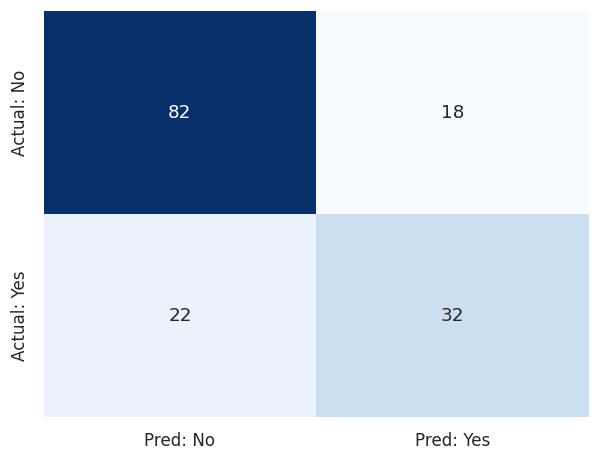

In [63]:
# Heatmap of the confusion matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred: No", "Pred: Yes"], yticklabels=["Actual: No", "Actual: Yes"])
plt.show()

In [64]:
# Classification report
print(classification_report(y_test, pred_test, target_names=["No diabetes", "Diabetes"]))

              precision    recall  f1-score   support

 No diabetes       0.79      0.82      0.80       100
    Diabetes       0.64      0.59      0.62        54

    accuracy                           0.74       154
   macro avg       0.71      0.71      0.71       154
weighted avg       0.74      0.74      0.74       154



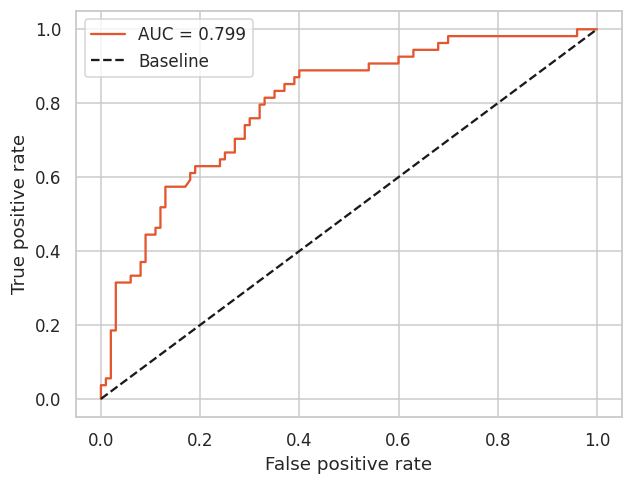

In [65]:
# ROC curve
fpr, tpr, _ = roc_curve(y_test, proba_test)
plt.plot(fpr, tpr, color=colors[1], label=f"AUC = {roc_auc_score(y_test, proba_test):.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Baseline")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.show()

# **Decision Threshold**

In [66]:
oof_proba = cross_val_predict(best_est, X_train, y_train, cv=cv_grid, method="predict_proba")[:, 1]

In [67]:
rows = []
for t in np.arange(0.20, 0.71, 0.05):
    p = (oof_proba >= t).astype(int)
    rows.append({"Threshold": round(t, 2),
                 "Precision": precision_score(y_train, p, zero_division=0),
                 "Recall": recall_score(y_train, p),
                 "F1": f1_score(y_train, p),
                 "F2": fbeta_score(y_train, p, beta=2)})
thr_tbl = pd.DataFrame(rows).set_index("Threshold").round(3)
thr_tbl

,Precision,Recall,F1,F2
Threshold,,,,
0.20,0.533,0.907,0.671,0.795
0.25,0.569,0.827,0.674,0.758
0.30,0.599,0.766,0.672,0.726
0.35,0.623,0.710,0.664,0.691
0.40,0.664,0.664,0.664,0.664
0.45,0.686,0.621,0.652,0.633
0.50,0.725,0.579,0.644,0.604
0.55,0.758,0.528,0.623,0.562
0.60,0.808,0.491,0.610,0.532


In [68]:
# Best threshold = highest F2
THRESHOLD = float(thr_tbl["F2"].idxmax())
print("Chosen threshold:", THRESHOLD)

Chosen threshold: 0.2


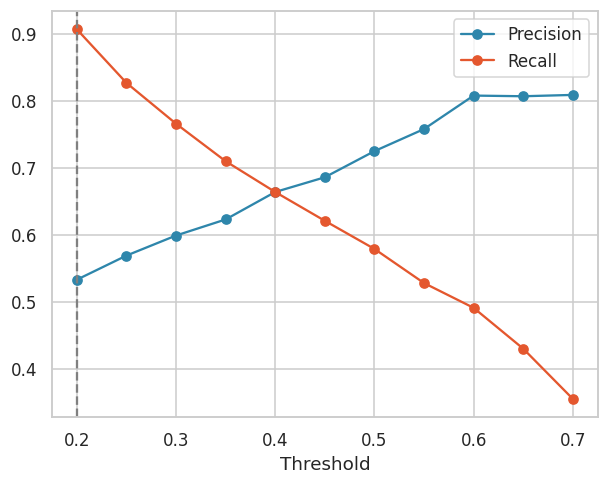

In [69]:
# Precision and recall against threshold
plt.plot(thr_tbl.index, thr_tbl["Precision"], marker="o", label="Precision", color=colors[0])
plt.plot(thr_tbl.index, thr_tbl["Recall"], marker="o", label="Recall", color=colors[1])
plt.axvline(THRESHOLD, color="grey", linestyle="--")
plt.xlabel("Threshold")
plt.legend()
plt.show()

In [70]:
# Test set: default 0.5 vs chosen threshold
pd.DataFrame({"Threshold 0.5": metric_row(best_est, X_test, y_test, 0.5),
              f"Threshold {THRESHOLD}": metric_row(best_est, X_test, y_test, THRESHOLD)}).T.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Threshold 0.5,0.740,0.640,0.593,0.615,0.799
Threshold 0.2,0.662,0.511,0.889,0.649,0.799


In [71]:
# Missed patients and false alarms
pred_screen = (proba_test >= THRESHOLD).astype(int)
cm2 = confusion_matrix(y_test, pred_screen)
print(f"Threshold 0.5   -> missed: {cm[1, 0]}, false alarms: {cm[0, 1]}")
print(f"Threshold {THRESHOLD} -> missed: {cm2[1, 0]}, false alarms: {cm2[0, 1]}")

Threshold 0.5   -> missed: 22, false alarms: 18
Threshold 0.2 -> missed: 6, false alarms: 46


# **Error Analysis**

In [72]:
err = X_test.copy()
err["Outcome"] = y_test.values
err["Predicted"] = pred_test

In [73]:
err["Result"] = np.select(
    [(err.Outcome == 1) & (err.Predicted == 1),
     (err.Outcome == 1) & (err.Predicted == 0),
     (err.Outcome == 0) & (err.Predicted == 1),
     (err.Outcome == 0) & (err.Predicted == 0)],
    ["True positive", "False negative (missed)", "False positive", "True negative"],
    default="Unknown")
err["Result"].value_counts()

,count
Result,
True negative,82
True positive,32
False negative (missed),22
False positive,18


In [74]:
order_res = ["True positive", "False negative (missed)", "False positive", "True negative"]
err.groupby("Result")[features].mean().reindex(order_res).round(1)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Result,,,,,,,,
True positive,5.7,155.9,66.7,21.7,116.8,36.7,0.6,38.7
False negative (missed),4.7,116.9,70.1,16.6,52.1,32.2,0.5,32.8
False positive,5.3,154.1,76.9,25.6,158.2,36.5,0.4,36.4
True negative,2.8,100.9,65.5,18.2,64.1,29.3,0.4,29.6


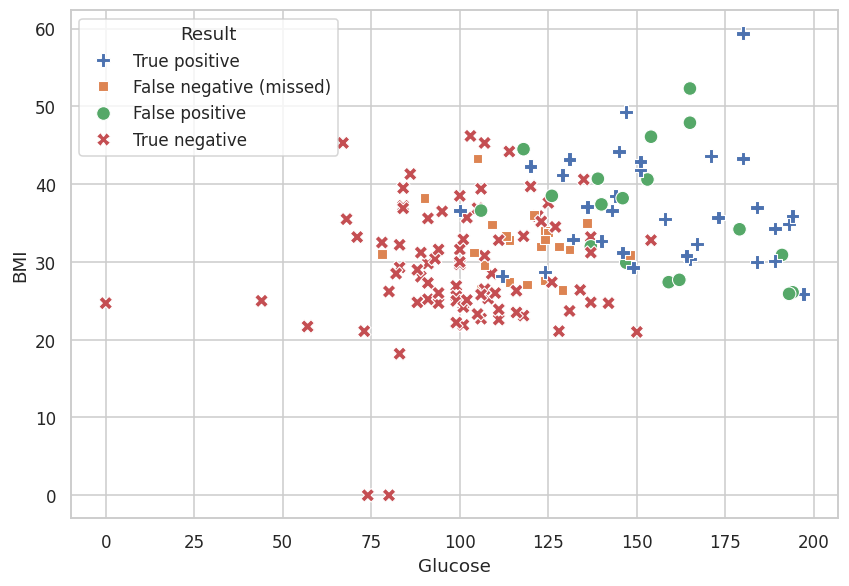

In [75]:
# Glucose vs BMI, colored by result
plt.figure(figsize=(9, 6))
sns.scatterplot(data=err, x="Glucose", y="BMI", hue="Result", hue_order=order_res, style="Result", s=80)
plt.show()

# **Subgroup Analysis**

In [76]:
sub = X_train.copy()
sub["Outcome"] = y_train.values
sub["Predicted"] = (oof_proba >= 0.5).astype(int)

In [77]:
# Make the groups
sub["Age group"] = pd.cut(sub["Age"], bins=[20, 30, 40, 50, 120], labels=["21-30", "31-40", "41-50", "51+"])
sub["BMI group"] = pd.cut(sub["BMI"], bins=[0, 25, 30, 100], right=False, labels=["Under 25", "25-29.9", "30+"])
sub["BMI group"] = sub["BMI group"].cat.add_categories("Not recorded").fillna("Not recorded")
sub["Pregnancies group"] = pd.cut(sub["Pregnancies"], bins=[-1, 0, 3, 30], labels=["0", "1-3", "4+"])

In [78]:
# Function: scores for each group
def subgroup_report(frame, col):
    rows = []
    for g, d in frame.groupby(col, observed=True):
        pos = int((d.Outcome == 1).sum())
        rows.append({"Group": g, "Patients": len(d), "Diabetic": pos,
                     "Accuracy": (d.Outcome == d.Predicted).mean(),
                     "Recall": ((d.Predicted == 1) & (d.Outcome == 1)).sum() / pos if pos else np.nan})
    return pd.DataFrame(rows).set_index("Group").round(3)

In [79]:
# Showing the three tables
reports = {}
for col in ["Age group", "BMI group", "Pregnancies group"]:
    reports[col] = subgroup_report(sub, col)
    print(col)
    display(reports[col])

Age group


,Patients,Diabetic,Accuracy,Recall
Group,,,,
21-30,328,72,0.851,0.472
31-40,130,58,0.708,0.603
41-50,89,51,0.607,0.569
51+,67,33,0.776,0.788


BMI group


,Patients,Diabetic,Accuracy,Recall
Group,,,,
Under 25,94,9,0.947,0.556
25-29.9,141,30,0.780,0.300
30+,379,175,0.734,0.629


Pregnancies group


,Patients,Diabetic,Accuracy,Recall
Group,,,,
0,85,31,0.765,0.516
1-3,253,62,0.826,0.484
4+,276,121,0.736,0.645


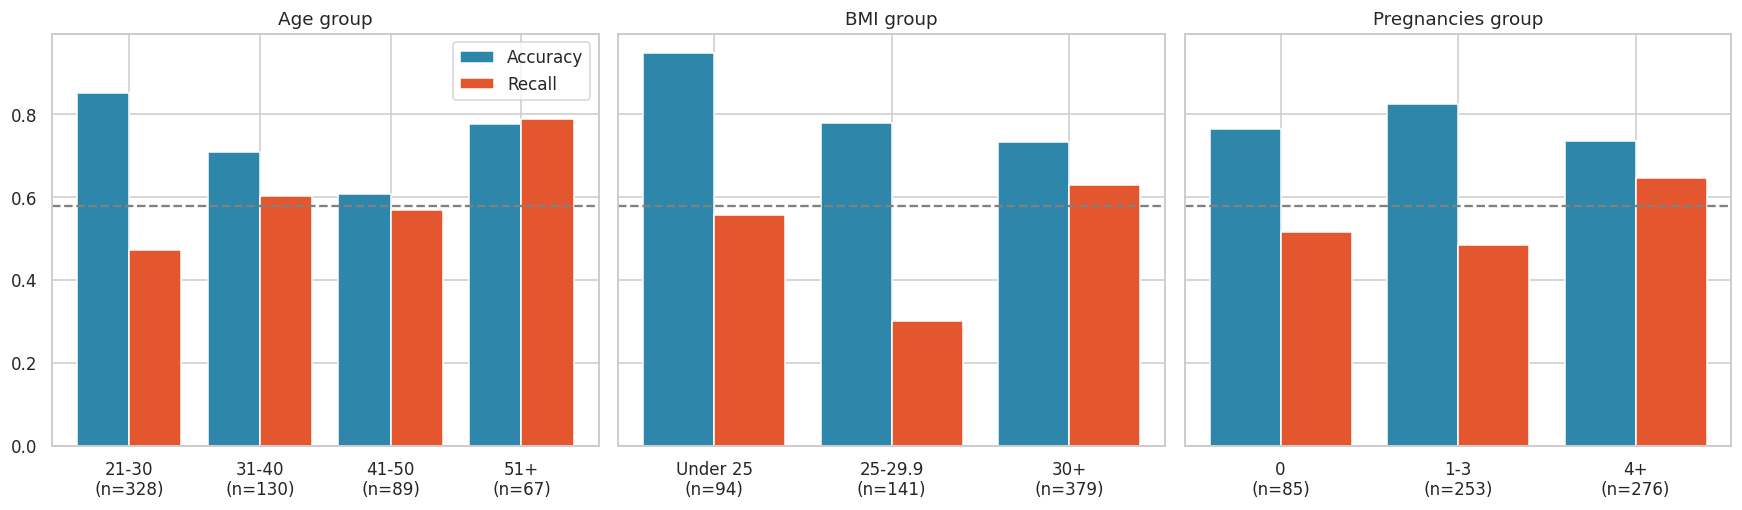

In [80]:
# Chart: accuracy and recall for each group
overall_recall = recall_score(y_train, sub["Predicted"])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (col, rep) in zip(axes, reports.items()):
    x = np.arange(len(rep))
    ax.bar(x - 0.2, rep["Accuracy"], width=0.4, label="Accuracy", color=colors[0])
    ax.bar(x + 0.2, rep["Recall"], width=0.4, label="Recall", color=colors[1])
    ax.axhline(overall_recall, color="grey", linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{g}\n(n={n})" for g, n in zip(rep.index, rep["Patients"])])
    ax.set_title(col)
axes[0].legend()
plt.tight_layout()
plt.show()

# **Feature Importance**

In [81]:
pi = permutation_importance(best_est, X_test, y_test, scoring="roc_auc",
                            n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()

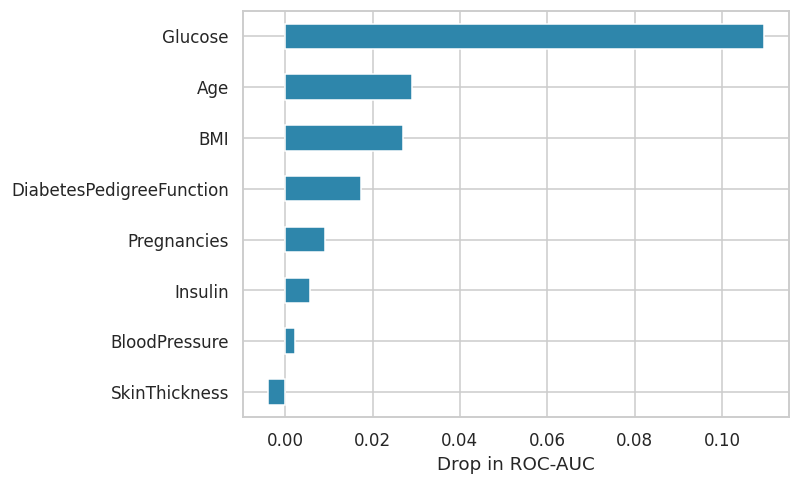

In [82]:
imp.plot(kind="barh", color=colors[0])
plt.xlabel("Drop in ROC-AUC")
plt.show()

# **PCA (Exploratory)**

In [83]:
prep = Pipeline([("imputer", SimpleImputer(strategy="median")),
                 ("scaler", StandardScaler())]).fit(X_train)
Z_train = prep.transform(X_train)
pca = PCA(n_components=8, random_state=SEED).fit(Z_train)

In [84]:
# Variance explained by each component
evr = pca.explained_variance_ratio_
print(evr.round(3))
print("First two components:", round(evr[:2].sum(), 3))

[0.261 0.218 0.131 0.105 0.097 0.086 0.055 0.047]
First two components: 0.479


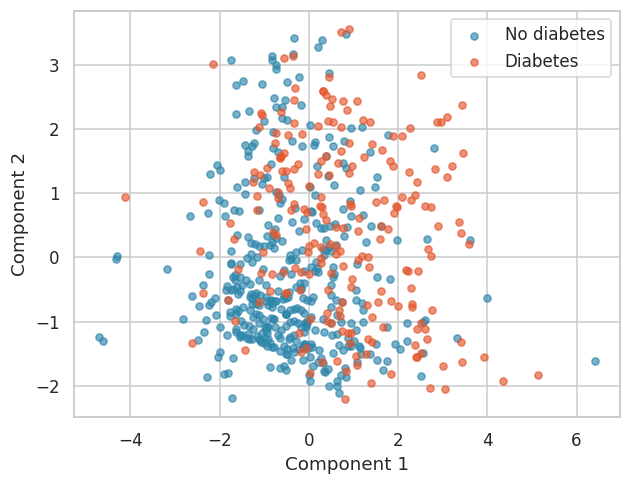

In [85]:
# Patients on the first two components
Z2 = pca.transform(Z_train)[:, :2]
for c in [0, 1]:
    m = (y_train.values == c)
    plt.scatter(Z2[m, 0], Z2[m, 1], s=22, alpha=0.65, color=colors[c], label=class_names[c])
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.legend()
plt.show()

# **Saving the Model (joblib)**

In [86]:
os.makedirs("models", exist_ok=True)
MODEL_PATH = "models/diabetes_pipeline.joblib"
joblib.dump(best_est, MODEL_PATH)
print("Saved:", MODEL_PATH)

Saved: models/diabetes_pipeline.joblib


In [87]:
loaded = joblib.load(MODEL_PATH)
print("Same predictions:", np.allclose(loaded.predict_proba(X_test), best_est.predict_proba(X_test)))

Same predictions: True


In [88]:
# A new patient (Insulin and SkinThickness not measured)
new_patient = pd.DataFrame([{
    "Pregnancies": 2, "Glucose": 148, "BloodPressure": 72, "SkinThickness": np.nan,
    "Insulin": np.nan, "BMI": 33.6, "DiabetesPedigreeFunction": 0.5, "Age": 45}])[X_train.columns]
new_patient

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,2,148,72,NaN,NaN,33.6,0.5,45


In [89]:
# Predict for the new patient
risk = loaded.predict_proba(new_patient)[0, 1]
print(f"Chance of diabetes: {risk:.1%}")
print("Refer for lab test" if risk >= THRESHOLD else "Low risk")

Chance of diabetes: 69.4%
Refer for lab test


In [90]:
# Requirements file
packages = ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn", "joblib"]
text = "\n".join(f"{p}=={version(p)}" for p in packages) + "\n"
open("requirements.txt", "w").write(text)
print(text)

numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0



# **Results Summary**

In [91]:
# Baseline vs best model
pd.DataFrame({
    "Baseline": metric_row(baseline_est, X_test, y_test),
    "Best model (0.5)": metric_row(best_est, X_test, y_test),
    f"Best model ({THRESHOLD})": metric_row(best_est, X_test, y_test, THRESHOLD),
}).T.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.649,0.000,0.000,0.000,0.500
Best model (0.5),0.740,0.640,0.593,0.615,0.799
Best model (0.2),0.662,0.511,0.889,0.649,0.799


In [ ]:
from google.colab import drive
drive.mount('/content/drive')